# 1 - General
## ISYE 4031 — Milestone 2: Angelo's Exploratory Analysis
Upload `epl_merged_data.xlsx` to your Colab session, then run the cells from top to bottom. The notebook reads that file directly, so it needs to be in the session folder before you start.

We want to see how final league points relate to three things: whether a team was newly promoted, how it performed in its first 10 matches, and how much it spent during the summer transfer window. We'll use the 2016/17–2022/23 training seasons and leave the later seasons for the group's model evaluation. Each row represents one team in one season.

We'll use the methods covered in class: summary statistics, scatterplots, and Pearson correlation. The code uses pandas, openpyxl, and matplotlib, which are normally available in Colab.

One detail still needs checking: the files don't identify the currency used for transfer fees. For now, the spending plot uses millions of the original currency units. Once the group confirms the currency, update `CURRENCY` in the next cell. That changes the label only.

Running everything saves the table, both plots, and a draft of the report section in your session folder.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

data = pd.read_excel("epl_merged_data.xlsx")
CURRENCY = "original currency units"  # Update this label once the group confirms the currency.

required = ["Season", "Team", "Promoted", "EOS_Total_Points", "Curr_Points",
            "Fee_Spending", "Missing_In_Fees_Count"]
assert all(column in data.columns for column in required), "Required columns are missing."
assert not data.duplicated(["Season", "Team"]).any(), "Duplicate club-season rows."
assert not data[required].isna().any().any(), "Missing values in analysis columns."
assert data["Promoted"].isin([0, 1]).all(), "Promotion status must be 0 or 1."

eda_data = data[data["Season"].between(2016, 2022)].copy()
assert len(eda_data) > 0, "No observations in the training period."
print("Training observations:", len(eda_data))
print("Seasons: 2016/17–2022/23")
print("We will use these training observations for the table and both plots.")

plt.rcParams.update({"font.size": 11, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})


Training observations: 140
Seasons: 2016/17–2022/23
We will use these training observations for the table and both plots.


# 2 - Compare Promoted and Returning Teams
First, we'll compare the final points of teams already in the Premier League with those that were newly promoted. The table shows how many observations are in each group, their mean and median, and how much their results vary.

This gives us a starting point for deciding whether promotion status could help explain final points. We're describing the differences here, without running a hypothesis test. We also need to remember that some clubs appear in several seasons and teams play against one another.

,n,Mean,Median,SD,Minimum,Maximum
Promoted,,,,,,
Returning,119,55.40,52.0,18.22,16,100
Promoted,21,37.29,37.0,11.52,21,59


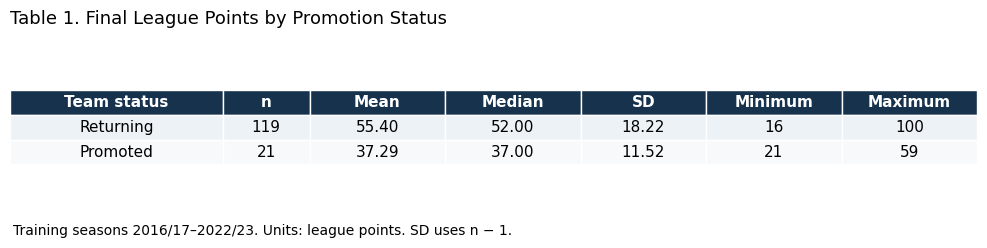

In [5]:
summary = eda_data.groupby("Promoted")["EOS_Total_Points"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)
summary.index = summary.index.map({0: "Returning", 1: "Promoted"})
summary.columns = ["n", "Mean", "Median", "SD", "Minimum", "Maximum"]
display(summary.round(2))

table_rows = []
for group, row in summary.iterrows():
    table_rows.append([group, int(row["n"]), f'{row["Mean"]:.2f}',
                       f'{row["Median"]:.2f}', f'{row["SD"]:.2f}',
                       f'{row["Minimum"]:.0f}', f'{row["Maximum"]:.0f}'])

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.axis("off")
ax.set_title("Table 1. Final League Points by Promotion Status", loc="left", pad=18)
table = ax.table(cellText=table_rows,
                 colLabels=["Team status", "n", "Mean", "Median", "SD", "Minimum", "Maximum"],
                 colWidths=[0.22, 0.09, 0.14, 0.14, 0.13, 0.14, 0.14],
                 cellLoc="center", loc="center")
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.9)
for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor("white")
    if r == 0:
        cell.set_facecolor("#17324d")
        cell.set_text_props(color="white", weight="bold")
    else:
        cell.set_facecolor("#edf2f6" if r == 1 else "#f7f9fb")
fig.text(0.02, 0.07, "Training seasons 2016/17–2022/23. Units: league points. SD uses n − 1.", fontsize=10)
plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.savefig("table1_promotion_summary.png", dpi=300, bbox_inches="tight")
plt.show()


# 3 - Compare Early-Season Points With Final Points
Next, we'll look at whether teams that start well also finish with more points. Each dot represents one team in one season. The colors show whether the team was returning or newly promoted.

We'll calculate Pearson's correlation, r, to describe the strength and direction of the linear relationship. The first 10 matches are already part of the final total, so a strong correlation is not enough to show how accurately we can predict the rest of the season.

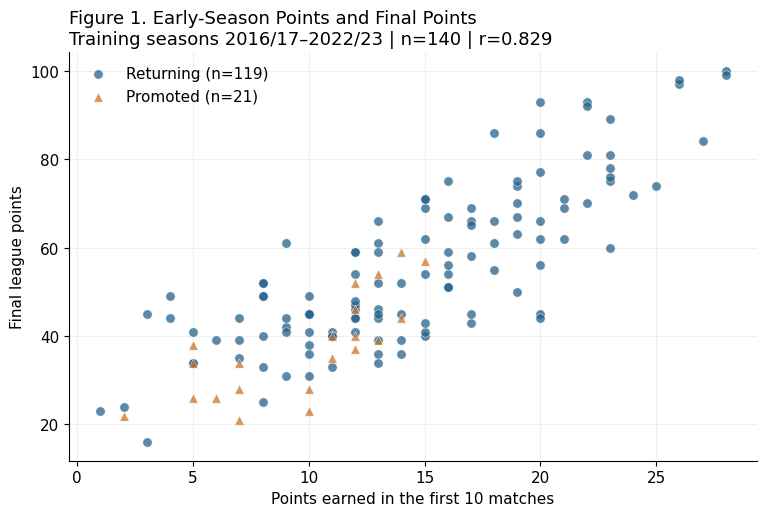

Pearson correlation: 0.829


In [7]:
early_r = eda_data["Curr_Points"].corr(eda_data["EOS_Total_Points"])

fig, ax = plt.subplots(figsize=(7.8, 5.3))
for status, label, color, marker in [(0, "Returning", "#25628a", "o"),
                                     (1, "Promoted", "#c87528", "^")]:
    group = eda_data[eda_data["Promoted"] == status]
    ax.scatter(group["Curr_Points"], group["EOS_Total_Points"],
               label=f"{label} (n={len(group)})", color=color, marker=marker,
               s=45, alpha=0.75, edgecolor="white", linewidth=0.4)
ax.set_xlabel("Points earned in the first 10 matches")
ax.set_ylabel("Final league points")
ax.set_title(f"Figure 1. Early-Season Points and Final Points\nTraining seasons 2016/17–2022/23 | n={len(eda_data)} | r={early_r:.3f}", loc="left")
ax.grid(alpha=0.18)
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("figure1_early_points.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Pearson correlation: {early_r:.3f}")


# 4 - Compare Summer Spending With Final Points
Now we'll look at recorded summer spending on incoming players. We'll show spending in millions to make the axis easier to read and use a different marker for teams with missing incoming transfer fees.

The totals only include fees that were recorded. A missing fee doesn't mean a player cost nothing, so some totals may be lower than the actual spending. We'll keep those observations and make that limitation clear.

The plot and correlation will show whether spending and final points tend to move together. They won't tell us whether spending caused better results or whether it adds useful information once we account for early-season performance.

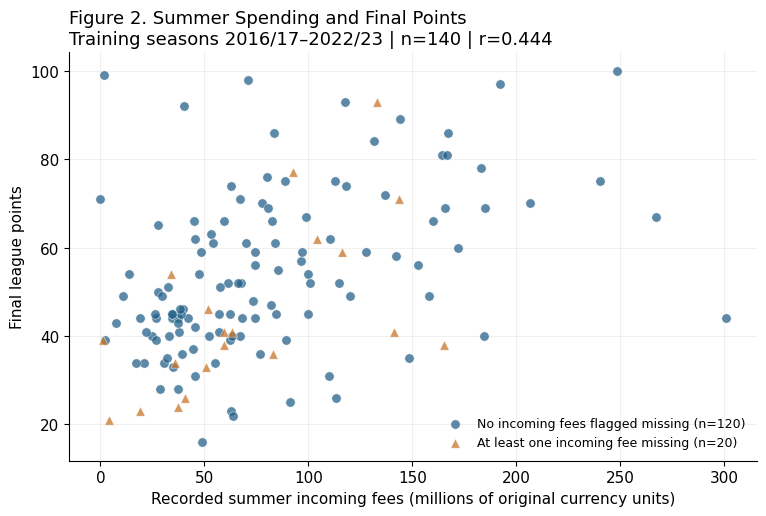

Pearson correlation: 0.444
Club-seasons with missing incoming fees: 20/140 (14.3%)


In [9]:
spending_r = eda_data["Fee_Spending"].corr(eda_data["EOS_Total_Points"])
missing_incoming = eda_data["Missing_In_Fees_Count"] > 0
missing_n = int(missing_incoming.sum())

fig, ax = plt.subplots(figsize=(7.8, 5.3))
for flag, label, color, marker in [
    (False, "No incoming fees flagged missing", "#25628a", "o"),
    (True, "At least one incoming fee missing", "#c87528", "^")]:
    group = eda_data[missing_incoming == flag]
    ax.scatter(group["Fee_Spending"] / 1_000_000, group["EOS_Total_Points"],
               label=f"{label} (n={len(group)})", color=color, marker=marker,
               s=45, alpha=0.75, edgecolor="white", linewidth=0.4)
ax.set_xlabel(f"Recorded summer incoming fees (millions of {CURRENCY})")
ax.set_ylabel("Final league points")
ax.set_title(f"Figure 2. Summer Spending and Final Points\nTraining seasons 2016/17–2022/23 | n={len(eda_data)} | r={spending_r:.3f}", loc="left")
ax.grid(alpha=0.18)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig("figure2_summer_spending.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Pearson correlation: {spending_r:.3f}")
print(f"Club-seasons with missing incoming fees: {missing_n}/{len(eda_data)} ({100*missing_n/len(eda_data):.1f}%)")


# 5 - Explain What We Found
This last cell brings the results together in a draft for the report. It fills in the numbers from our calculations and saves the text as `angelo_report_section.md`. Add the table and plots where the draft indicates.

The explanations below are based on the supplied dataset. If the data change, check that the descriptions still match the results. Our goal here is to identify useful patterns for the group to investigate; Nico's section covers the baseline model and its performance.

In [10]:
returning = summary.loc["Returning"]
promoted = summary.loc["Promoted"]
gap = returning["Mean"] - promoted["Mean"]

report = f"""## 4. Exploratory Data Analysis

We started by looking at how final Premier League points relate to promotion status, points earned in the first 10 matches, and summer transfer spending. We used the {len(eda_data)} team-season observations from 2016/17–2022/23, which are the same training seasons used for the baseline. Each observation represents one team in one season. We left the 2023/24–2025/26 seasons out of this exploration so they could be used for model evaluation.

[Insert Table 1: table1_promotion_summary.png]

Table 1 shows a clear difference between returning and newly promoted teams. Returning teams averaged {returning['Mean']:.2f} final points across {int(returning['n'])} observations, while promoted teams averaged {promoted['Mean']:.2f} across {int(promoted['n'])} observations. That is a gap of {gap:.2f} points. The medians show a similar pattern: {returning['Median']:.0f} points for returning teams and {promoted['Median']:.0f} for promoted teams. Returning teams also had a wider spread in their results, with a standard deviation of {returning['SD']:.2f} points compared with {promoted['SD']:.2f}. This suggests that promotion status could be useful in the model. It also helps explain why the baseline struggles with promoted teams, since assigning them the overall training average can put their predictions too high. Still, the groups overlap, and some promoted teams finish with more points than returning teams.

[Insert Figure 1: figure1_early_points.png]

Figure 1 shows that teams with more points after their first 10 matches generally finish the season with more points as well. The correlation is {early_r:.3f}, indicating a strong positive linear relationship. There is still noticeable variation: teams with similar starts can end the season with different totals. Early-season points look useful for our prediction question because they are available when we make the prediction after Match 10. However, these points are already included in the final total. We therefore cannot use the correlation alone as evidence that the model will accurately predict the remaining matches or perform well on new seasons.

[Insert Figure 2: figure2_summer_spending.png]

Figure 2 shows a positive relationship between recorded summer spending and final points, but the pattern is less clear than it is for early-season points. The correlation is {spending_r:.3f}, and teams with similar spending often finish with quite different totals. Spending may still be useful, but we would need to check whether it adds information beyond early performance and promotion status. The plot shows spending in millions of the original currency units because the source currency has not yet been confirmed. Also, {missing_n} of the {len(eda_data)} training observations ({100*missing_n/len(eda_data):.1f}%) have at least one missing incoming transfer fee, so their recorded totals may be below what they actually spent. We also cannot conclude that spending causes higher final points. Stronger teams may both spend more and perform better for other reasons.

Overall, early-season points show the strongest of the two correlations we examined, and the difference between promoted and returning teams makes promotion status worth including in the next stage. Summer spending is also worth investigating, although its relationship with final points is less clear and the missing fees make it harder to interpret. These findings give us a starting point for the regression analysis, rather than proving which combination of variables will predict best. Since clubs appear across multiple seasons and compete against each other, the observations are not fully independent. The next stage should check the model's assumptions and evaluate its predictions using the chronological split.
"""
display(Markdown(report))
with open("angelo_report_section.md", "w", encoding="utf-8") as file:
    file.write(report)


## 4. Exploratory Data Analysis

We started by looking at how final Premier League points relate to promotion status, points earned in the first 10 matches, and summer transfer spending. We used the 140 team-season observations from 2016/17–2022/23, which are the same training seasons used for the baseline. Each observation represents one team in one season. We left the 2023/24–2025/26 seasons out of this exploration so they could be used for model evaluation.

[Insert Table 1: table1_promotion_summary.png]

Table 1 shows a clear difference between returning and newly promoted teams. Returning teams averaged 55.40 final points across 119 observations, while promoted teams averaged 37.29 across 21 observations. That is a gap of 18.12 points. The medians show a similar pattern: 52 points for returning teams and 37 for promoted teams. Returning teams also had a wider spread in their results, with a standard deviation of 18.22 points compared with 11.52. This suggests that promotion status could be useful in the model. It also helps explain why the baseline struggles with promoted teams, since assigning them the overall training average can put their predictions too high. Still, the groups overlap, and some promoted teams finish with more points than returning teams.

[Insert Figure 1: figure1_early_points.png]

Figure 1 shows that teams with more points after their first 10 matches generally finish the season with more points as well. The correlation is 0.829, indicating a strong positive linear relationship. There is still noticeable variation: teams with similar starts can end the season with different totals. Early-season points look useful for our prediction question because they are available when we make the prediction after Match 10. However, these points are already included in the final total. We therefore cannot use the correlation alone as evidence that the model will accurately predict the remaining matches or perform well on new seasons.

[Insert Figure 2: figure2_summer_spending.png]

Figure 2 shows a positive relationship between recorded summer spending and final points, but the pattern is less clear than it is for early-season points. The correlation is 0.444, and teams with similar spending often finish with quite different totals. Spending may still be useful, but we would need to check whether it adds information beyond early performance and promotion status. The plot shows spending in millions of the original currency units because the source currency has not yet been confirmed. Also, 20 of the 140 training observations (14.3%) have at least one missing incoming transfer fee, so their recorded totals may be below what they actually spent. We also cannot conclude that spending causes higher final points. Stronger teams may both spend more and perform better for other reasons.

Overall, early-season points show the strongest of the two correlations we examined, and the difference between promoted and returning teams makes promotion status worth including in the next stage. Summer spending is also worth investigating, although its relationship with final points is less clear and the missing fees make it harder to interpret. These findings give us a starting point for the regression analysis, rather than proving which combination of variables will predict best. Since clubs appear across multiple seasons and compete against each other, the observations are not fully independent. The next stage should check the model's assumptions and evaluate its predictions using the chronological split.
